# 02: monitoring the training and diagnosing its failures (milestone m2)

Same data and same dense baseline as `01_dense_baseline.ipynb` (milestone m1). Here we follow Session 6 and TP06: we
plot the training and validation curves, read them, check that the training itself works, and measure what each tool
against overfitting changes.

## Imports

- `torch`, `torch.nn`: the networks; `DataLoader` and `TensorDataset` serve mini-batches from tensors.
- `torchvision.datasets`: `ImageFolder` reads the subset (one folder per genre).
- `copy`: `copy.deepcopy` makes an independent copy of the weights (for early stopping).
- `pandas`: reads `metadata.csv` (the artist of each image) and holds the comparison table.
- `numpy`, `matplotlib`: arrays and training curves.

In [1]:
import os
import copy
import math
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
import torch.nn as nn
from torch.utils.data import DataLoader, TensorDataset
from torchvision import datasets

DATA_DIR = "data/wikiart_genre5"
np.random.seed(0)
torch.manual_seed(0)
torch.set_num_threads(2)
device = "cuda" if torch.cuda.is_available() else "cpu"
print("device:", device)

device: cpu


## Helper functions

The training tools of TP06:

- `train_one_epoch(model, loader, loss_fn, optimizer)`: one pass over the training data with the 5 lines of the
  training loop; returns the mean training loss.
- `evaluate(model, loader, loss_fn)`: returns `(mean loss, accuracy)` in evaluation mode, without gradients.
- `fit(model, optimizer, n_epochs, ...)`: trains for `n_epochs` and returns a **history**, a dictionary of lists with
  one value per epoch: `"train_loss"`, `"train_acc"`, `"val_loss"`, `"val_acc"`, `"lr"`. The train metrics are
  measured in evaluation mode on the whole training set after each epoch (`record`), so that train and validation
  are measured the same way.
- `plot_history(history)` and `plot_compare(histories, key)`: the curves.

In [2]:
def train_one_epoch(model, loader, loss_fn, optimizer):
    model.train()
    total, n = 0.0, 0
    for xb, yb in loader:
        xb, yb = xb.to(device), yb.to(device)
        optimizer.zero_grad()
        loss = loss_fn(model(xb), yb)
        loss.backward()
        optimizer.step()
        total += loss.item() * len(yb)
        n += len(yb)
    return total / n


def evaluate(model, loader, loss_fn):
    model.eval()
    total, correct, n = 0.0, 0, 0
    with torch.no_grad():
        for xb, yb in loader:
            xb, yb = xb.to(device), yb.to(device)
            out = model(xb)
            total += loss_fn(out, yb).item() * len(yb)
            correct += (out.argmax(dim=1) == yb).sum().item()
            n += len(yb)
    return total / n, correct / n


def new_history():
    return {"train_loss": [], "train_acc": [], "val_loss": [], "val_acc": [], "lr": []}


def record(history, model, optimizer):
    """Measure the model on the training and validation sets and append the results to the history."""
    tl, ta = evaluate(model, train_eval_loader, loss_fn)
    vl, va = evaluate(model, val_loader, loss_fn)
    history["train_loss"].append(tl); history["train_acc"].append(ta)
    history["val_loss"].append(vl); history["val_acc"].append(va)
    history["lr"].append(optimizer.param_groups[0]["lr"])


def fit(model, optimizer, n_epochs, train_epoch_fn=train_one_epoch, scheduler=None, verbose=False):
    torch.manual_seed(1)                       # same order of the mini-batches for every run
    history = new_history()
    for epoch in range(n_epochs):
        train_epoch_fn(model, train_loader, loss_fn, optimizer)
        record(history, model, optimizer)
        if scheduler is not None:
            scheduler.step()
        if verbose:
            print(f"epoch {epoch + 1:2d}  train loss {history['train_loss'][-1]:.3f}  "
                  f"val loss {history['val_loss'][-1]:.3f}  val acc {history['val_acc'][-1]:.3f}")
    return history


def plot_history(history, title=""):
    e = range(1, len(history["train_loss"]) + 1)
    fig, axes = plt.subplots(1, 2, figsize=(11, 3.5))
    axes[0].plot(e, history["train_loss"], label="train"); axes[0].plot(e, history["val_loss"], label="validation")
    axes[0].set_xlabel("epoch"); axes[0].set_ylabel("loss"); axes[0].legend()
    axes[1].plot(e, history["train_acc"], label="train"); axes[1].plot(e, history["val_acc"], label="validation")
    axes[1].set_xlabel("epoch"); axes[1].set_ylabel("accuracy"); axes[1].legend()
    fig.suptitle(title)
    plt.show()


def plot_compare(histories, key="val_loss"):
    plt.figure(figsize=(7, 3.5))
    for name, h in histories.items():
        plt.plot(range(1, len(h[key]) + 1), h[key], label=name)
    plt.xlabel("epoch"); plt.ylabel(key); plt.legend()
    plt.show()


def count_parameters(model):
    return sum(p.numel() for p in model.parameters())

## The data, exactly as in notebook 01

Same loading, same split by artist (seed 0: 1 000 / 250 / 250 images, 200 / 50 / 50 per genre, no named artist in
two sets), same standardisation with the training statistics only. The test set is not used in this notebook: it
was measured once, at the end of milestone m1.

In [3]:
folder = datasets.ImageFolder(DATA_DIR)
CLASSES = folder.classes
images = np.stack([np.array(img) for img, _ in folder])          # (N, 128, 128, 3), uint8, values 0 to 255
X_full = torch.tensor(images).permute(0, 3, 1, 2).float() / 255  # (N, 3, 128, 128), pixels in [0, 1]
y_full = torch.tensor(folder.targets)                             # (N,), int64

print("X_full", tuple(X_full.shape), X_full.dtype, "| y_full", tuple(y_full.shape), y_full.dtype)
print("images per class:", dict(zip(CLASSES, torch.bincount(y_full).tolist())))

X_full (1500, 3, 128, 128) torch.float32 | y_full (1500,) torch.int64
images per class: {'cityscape': 300, 'landscape': 300, 'portrait': 300, 'religious_painting': 300, 'still_life': 300}


In [4]:
meta = pd.read_csv(os.path.join(DATA_DIR, "metadata.csv")).set_index("path")
artist = [meta.loc[os.path.relpath(p, DATA_DIR), "artist"] for p, _ in folder.samples]
# one group per named artist; "Unknown Artist" is a catch-all of many painters, so each of its images is its own group
group = [a if a != "Unknown Artist" else f"unknown_{i}" for i, a in enumerate(artist)]
names = sorted(set(group))
members = {g: [i for i, h in enumerate(group) if h == g] for g in names}

# groups in a random order: a group goes to test if it fits there (at most 1/6 of each class), else to validation,
# else to train. Classes stay balanced and an artist never appears in two sets.
order = torch.randperm(len(names), generator=torch.Generator().manual_seed(0)).tolist()
per_class = torch.bincount(y_full) // 6                         # 50 images of each class in test and in validation
filled = {"test": torch.zeros(len(CLASSES), dtype=torch.int64), "val": torch.zeros(len(CLASSES), dtype=torch.int64)}
split = {"train": [], "val": [], "test": []}
for k in order:
    idx = members[names[k]]
    counts = torch.bincount(y_full[idx], minlength=len(CLASSES))
    s = next((s for s in ["test", "val"] if (filled[s] + counts <= per_class).all()), "train")
    if s != "train":
        filled[s] += counts
    split[s] += idx
train_idx, val_idx, test_idx = (torch.tensor(sorted(split[s])) for s in ["train", "val", "test"])

X_train_raw, y_train = X_full[train_idx], y_full[train_idx]
X_val_raw, y_val = X_full[val_idx], y_full[val_idx]
X_test_raw, y_test = X_full[test_idx], y_full[test_idx]

named = {s: {artist[i] for i in split[s]} - {"Unknown Artist"} for s in split}
assert not (named["train"] & named["val"] or named["train"] & named["test"] or named["val"] & named["test"]), "an artist is on both sides"
print(f"train {len(train_idx)}, val {len(val_idx)}, test {len(test_idx)} | no named artist in two sets")
for s, y in [("train", y_train), ("val", y_val), ("test", y_test)]:
    print(f"{s:5s}", dict(zip(CLASSES, torch.bincount(y, minlength=len(CLASSES)).tolist())))

train 1000, val 250, test 250 | no named artist in two sets
train {'cityscape': 200, 'landscape': 200, 'portrait': 200, 'religious_painting': 200, 'still_life': 200}
val   {'cityscape': 50, 'landscape': 50, 'portrait': 50, 'religious_painting': 50, 'still_life': 50}
test  {'cityscape': 50, 'landscape': 50, 'portrait': 50, 'religious_painting': 50, 'still_life': 50}


Standardisation and loaders, as in TP06: `train_loader` serves shuffled mini-batches of 64 for training;
`train_eval_loader` measures the whole training set (in evaluation mode, after each epoch); `val_loader` the
validation set.

In [5]:
mean = X_train_raw.mean().item()   # one number over all the training pixels
std = X_train_raw.std().item()
X_train = (X_train_raw - mean) / std
X_val = (X_val_raw - mean) / std

BATCH_SIZE = 64
train_loader = DataLoader(TensorDataset(X_train, y_train), batch_size=BATCH_SIZE, shuffle=True)
train_eval_loader = DataLoader(TensorDataset(X_train, y_train), batch_size=1000)
val_loader = DataLoader(TensorDataset(X_val, y_val), batch_size=1000)
loss_fn = nn.CrossEntropyLoss()
print(f"mean {mean:.4f}, std {std:.4f} | train {tuple(X_train.shape)}, validation {tuple(X_val.shape)}")

mean 0.4547, std 0.2538 | train (1000, 3, 128, 128), validation (250, 3, 128, 128)


## The training curves of the baseline

Same network and same recipe as milestone m1 (49 152 → 128 sigmoid → 5, plain SGD with a learning rate of 0.2), but
trained for 30 epochs instead of 10, as in TP06, to see where the curves go. `make_baseline()` builds a fresh network
each time we need one. After each epoch, `fit` measures the loss and the accuracy on the whole training set and on the
validation set: course 6, *"always plot both"*.

epoch  1  train loss 1.386  val loss 1.518  val acc 0.384
epoch  2  train loss 1.326  val loss 1.514  val acc 0.324


epoch  3  train loss 1.305  val loss 1.536  val acc 0.320
epoch  4  train loss 1.086  val loss 1.458  val acc 0.380


epoch  5  train loss 1.135  val loss 1.524  val acc 0.392
epoch  6  train loss 1.014  val loss 1.557  val acc 0.368


epoch  7  train loss 0.848  val loss 1.484  val acc 0.392
epoch  8  train loss 0.880  val loss 1.547  val acc 0.348


epoch  9  train loss 0.844  val loss 1.722  val acc 0.336
epoch 10  train loss 0.666  val loss 1.514  val acc 0.384


epoch 11  train loss 0.934  val loss 1.784  val acc 0.352
epoch 12  train loss 0.621  val loss 1.524  val acc 0.408


... (6 outputs left out)

epoch 24  train loss 0.336  val loss 1.648  val acc 0.420
epoch 25  train loss 0.494  val loss 1.847  val acc 0.388


epoch 26  train loss 0.456  val loss 1.954  val acc 0.368
epoch 27  train loss 0.384  val loss 1.901  val acc 0.384


epoch 28  train loss 0.299  val loss 1.899  val acc 0.344
epoch 29  train loss 0.315  val loss 1.901  val acc 0.380


epoch 30  train loss 0.253  val loss 1.813  val acc 0.408


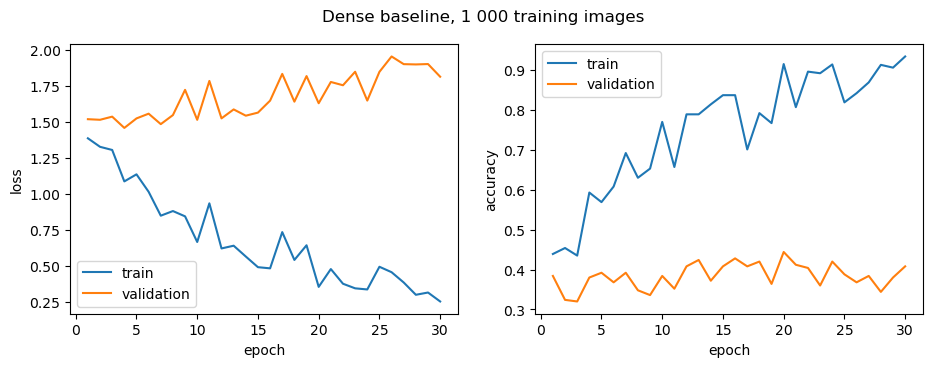

In [6]:
N_IN = 3 * 128 * 128
EPOCHS = 30
LR = 0.2


def make_baseline():
    return nn.Sequential(
        nn.Flatten(),
        nn.Linear(N_IN, 128),
        nn.Sigmoid(),
        nn.Linear(128, len(CLASSES)),
    ).to(device)


torch.manual_seed(0)
model_base = make_baseline()
optimizer = torch.optim.SGD(model_base.parameters(), lr=LR)
history_base = fit(model_base, optimizer, EPOCHS, verbose=True)
plot_history(history_base, "Dense baseline, 1 000 training images")

## Measure the overfitting

As in TP06 (Exercise 3), two numbers from `history_base`:

- `gap_base`: final train accuracy minus final validation accuracy. A large gap means the network does much better on
  the images it trained on than on new ones.
- `best_epoch_base`: the epoch (counted from 1) where the validation loss is the smallest. Everything after it is
  wasted, even harmful, training.

In [7]:
gap_base = history_base["train_acc"][-1] - history_base["val_acc"][-1]
best_epoch_base = int(np.argmin(history_base["val_loss"])) + 1

print(f"final train accuracy {history_base['train_acc'][-1]:.3f} | final validation accuracy {history_base['val_acc'][-1]:.3f} "
      f"| gap {gap_base:.3f}")
print(f"best validation loss {min(history_base['val_loss']):.3f} at epoch {best_epoch_base} of {EPOCHS} "
      f"| final validation loss {history_base['val_loss'][-1]:.3f}")
print(f"start: train loss {history_base['train_loss'][0]:.3f} -> end: {history_base['train_loss'][-1]:.3f}")

final train accuracy 0.934 | final validation accuracy 0.408 | gap 0.526
best validation loss 1.458 at epoch 4 of 30 | final validation loss 1.813
start: train loss 1.386 -> end: 0.253


**What we see.** The curves show **overfitting** (Session 6). The training accuracy climbs to 0.93 while the validation
accuracy stays around 0.40 (between 0.32 and 0.44 over the 30 epochs): a gap of 0.53. The validation loss is the
best at epoch 4 (1.458), then rises to 1.81: the network becomes over-confident on paintings it has never seen. With
6.3 million parameters for 1 000 training images, it memorises its training set instead of learning the genres.

A second symptom: the training loss zigzags (it goes back up at epochs 5, 8, 11, 13, 17, 19, 21, 25 and 29, for example
0.666 at epoch 10 then 0.934 at epoch 11). Plain SGD with a learning rate of 0.2 takes steps that are too large to
settle: the "loss very noisy, does not settle" row of the diagnosis table of Session 6.

## Early stopping: keep the best validation epoch

The tool of Session 6 that follows directly from the curves: after each epoch, if the validation loss is the best so
far, save a copy of the weights (`copy.deepcopy(model.state_dict())`: without the deep copy, the "copy" would keep
following the training). If it has not improved for `patience` epochs, stop. At the end, reload the best weights.
Same network, same initial weights, same recipe as above: only the stopping rule changes (TP06, Exercise 10).

In [8]:
def fit_early_stopping(model, optimizer, max_epochs, patience):
    torch.manual_seed(1)
    history = new_history()
    best_loss, best_state, best_epoch, wait = float("inf"), None, 0, 0
    for epoch in range(1, max_epochs + 1):
        train_one_epoch(model, train_loader, loss_fn, optimizer)
        record(history, model, optimizer)
        val_loss = history["val_loss"][-1]
        if val_loss < best_loss:                                     # improvement: save a checkpoint
            best_loss, best_epoch, wait = val_loss, epoch, 0
            best_state = copy.deepcopy(model.state_dict())
        else:
            wait += 1
            if wait >= patience:                                     # no improvement for `patience` epochs
                break
    model.load_state_dict(best_state)                                # go back to the best epoch
    return history, best_epoch


torch.manual_seed(0)
model_es = make_baseline()
optimizer = torch.optim.SGD(model_es.parameters(), lr=LR)
history_es, best_epoch_es = fit_early_stopping(model_es, optimizer, max_epochs=EPOCHS, patience=5)

train_loss_es, train_acc_es = evaluate(model_es, train_eval_loader, loss_fn)
val_loss_es, val_acc_es = evaluate(model_es, val_loader, loss_fn)
print(f"stopped after {len(history_es['val_loss'])} epochs, best epoch {best_epoch_es}")
print(f"{'':16s} {'train acc':>9s} {'val acc':>8s} {'gap':>6s} {'val loss':>9s}")
print(f"{'baseline (30)':16s} {history_base['train_acc'][-1]:9.3f} {history_base['val_acc'][-1]:8.3f} {gap_base:6.3f} {history_base['val_loss'][-1]:9.3f}")
print(f"{'early stopping':16s} {train_acc_es:9.3f} {val_acc_es:8.3f} {train_acc_es - val_acc_es:6.3f} {val_loss_es:9.3f}")

stopped after 9 epochs, best epoch 4
                 train acc  val acc    gap  val loss
baseline (30)        0.934    0.408  0.526     1.813
early stopping       0.593    0.380  0.213     1.458


**What we see.** Early stopping stops after 9 epochs and keeps epoch 4. The validation loss of the kept model is 1.458
instead of 1.813, and the gap between train and validation falls from 0.53 to 0.21: the overfitting diagnosis is
confirmed, and 21 of the 30 epochs were wasted. But the validation accuracy does not improve (0.380 versus 0.408, a
difference of 7 images out of 250): stopping earlier avoids memorising, it does not teach the network to recognise the
genres better. As in TP06, no tool works miracles on 1 000 images; the limit is the dense network itself (milestone m3).

## Three more tools: weight decay, dropout, learning-rate decay

The failure diagnosis below names three more fixes from Session 6 that we had not tried. Here we measure each one
(TP06, Exercises 4 to 11). **One change at a time**, compared with the baseline: same initial weights (seed 0), plain
SGD with a learning rate of 0.2, 30 epochs, and `fit` resets the seed so the mini-batches come in the same order. (With
dropout the random masks use the same generator as the shuffling, so the batch order is not identical to the baseline's.)
Everything is chosen on the **validation** set; the test set is still untouched.

- **Weight decay** `wd`: `SGD(..., weight_decay=wd)` adds $\lambda w$ to each gradient, which pulls the weights toward 0
  (PyTorch applies it to the biases too). We try three values.
- **Dropout** `p`: an `nn.Dropout(p)` after the 128 sigmoid neurons drops each of them with probability `p` during
  training (and does nothing in evaluation mode). We try two values.
- **Learning-rate decay**: `CosineAnnealingLR(T_max=30)` lowers the learning rate from 0.2 to 0 along half a cosine, to
  fight the zigzag of the training loss seen above.
- **Combination**: the best weight decay, the best dropout and the cosine schedule together.

In [9]:
def make_dropout(p):
    return nn.Sequential(nn.Flatten(), nn.Linear(N_IN, 128), nn.Sigmoid(), nn.Dropout(p), nn.Linear(128, len(CLASSES))).to(device)


def run(make_model, wd=0.0, cosine=False):
    """Same recipe as the baseline (seed 0, SGD lr 0.2, 30 epochs), with one change."""
    torch.manual_seed(0)
    model = make_model()
    optimizer = torch.optim.SGD(model.parameters(), lr=LR, weight_decay=wd)
    scheduler = torch.optim.lr_scheduler.CosineAnnealingLR(optimizer, T_max=EPOCHS) if cosine else None
    return fit(model, optimizer, EPOCHS, scheduler=scheduler), model


histories = {"baseline": history_base}
for wd in [1e-4, 1e-3, 1e-2]:
    histories[f"weight decay {wd:g}"], _ = run(make_baseline, wd=wd)
for p in [0.3, 0.5]:
    histories[f"dropout {p}"], _ = run(lambda: make_dropout(p))
histories["cosine lr decay"], _ = run(make_baseline, cosine=True)
print("runs:", list(histories))

runs: ['baseline', 'weight decay 0.0001', 'weight decay 0.001', 'weight decay 0.01', 'dropout 0.3', 'dropout 0.5', 'cosine lr decay']


**Reading one run.** `row(history, i)` gives, for epoch index `i`, the validation accuracy, the gap (train accuracy minus
validation accuracy) and the validation loss. The final model is the last epoch (`-1`); for early stopping it is the
reloaded best epoch.

In [10]:
def row(history, i=-1):
    return [history["val_acc"][i], history["train_acc"][i] - history["val_acc"][i], history["val_loss"][i]]


def n_rises(h):
    """Number of epochs where the training loss goes back up (the zigzag of the noisy runs)."""
    return int(sum(b > a for a, b in zip(h["train_loss"], h["train_loss"][1:])))


table = {name: row(h) + [min(h["val_loss"]), int(np.argmin(h["val_loss"])) + 1, n_rises(h)] for name, h in histories.items()}
table["early stopping (m2)"] = row(history_es, best_epoch_es - 1) + [min(history_es["val_loss"]), best_epoch_es, np.nan]
results = pd.DataFrame.from_dict(table, orient="index",
                                 columns=["val acc", "gap", "final val loss", "best val loss", "best epoch", "train-loss rises"])
print(results.round(3).to_string())

                     val acc    gap  final val loss  best val loss  best epoch  train-loss rises
baseline               0.408  0.526           1.813          1.458           4               9.0
weight decay 0.0001    0.408  0.542           1.868          1.443           4              10.0
weight decay 0.001     0.440  0.497           1.734          1.423           4               9.0
weight decay 0.01      0.440  0.455           1.619          1.421           4              11.0
dropout 0.3            0.388  0.424           1.705          1.415           8              10.0
dropout 0.5            0.372  0.344           1.570          1.372           8              10.0
cosine lr decay        0.388  0.608           1.846          1.434           4               4.0
early stopping (m2)    0.380  0.213           1.458          1.458           4               NaN


We pick the best weight decay and the best dropout **by validation accuracy** (ties broken by the smaller gap), then
train the combination with the cosine schedule.

chosen: weight decay 0.01 | dropout 0.3
                                                   val acc    gap  final val loss  best val loss  best epoch  train-loss rises
baseline                                             0.408  0.526           1.813          1.458         4.0               9.0
weight decay 0.0001                                  0.408  0.542           1.868          1.443         4.0              10.0
weight decay 0.001                                   0.440  0.497           1.734          1.423         4.0               9.0
weight decay 0.01                                    0.440  0.455           1.619          1.421         4.0              11.0
dropout 0.3                                          0.388  0.424           1.705          1.415         8.0              10.0
dropout 0.5                                          0.372  0.344           1.570          1.372         8.0              10.0
cosine lr decay                                      0.388  0.608      

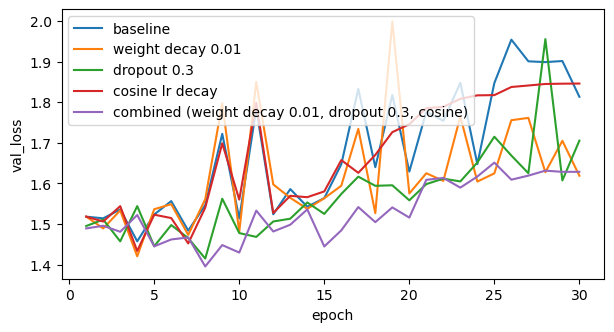

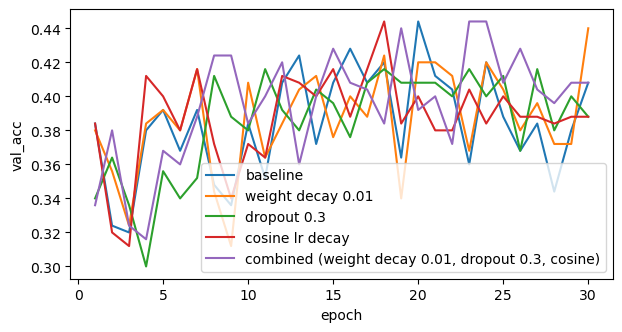

In [11]:
def best_of(prefix):
    names = [n for n in histories if n.startswith(prefix)]
    return max(names, key=lambda n: (round(results.loc[n, "val acc"], 3), -results.loc[n, "gap"]))


best_wd, best_p = best_of("weight decay"), best_of("dropout")
wd_value, p_value = float(best_wd.split()[-1]), float(best_p.split()[-1])
histories[f"combined ({best_wd}, {best_p}, cosine)"], _ = run(lambda: make_dropout(p_value), wd=wd_value, cosine=True)
name = list(histories)[-1]
results.loc[name] = row(histories[name]) + [min(histories[name]["val_loss"]), int(np.argmin(histories[name]["val_loss"])) + 1, n_rises(histories[name])]
print("chosen:", best_wd, "|", best_p)
print(results.round(3).to_string())
results.round(4).to_csv("results_m2_regularisation.csv")

plot_compare({k: histories[k] for k in ["baseline", best_wd, best_p, "cosine lr decay", name]}, "val_loss")
plot_compare({k: histories[k] for k in ["baseline", best_wd, best_p, "cosine lr decay", name]}, "val_acc")


**What we see.** The validation set has 250 images, so an accuracy has a margin of about ±0.06: every run lands
between 0.37 and 0.44, and **no tool moves the validation accuracy outside that margin**.

| Tool | What it changes | What it does not change |
|---|---|---|
| Weight decay 1e-3 and 1e-2 | Gap from 0.53 to 0.50 and 0.46; final validation loss from 1.81 to 1.73 and 1.62; validation accuracy 0.440 versus 0.408 (+8 images) | The gain in accuracy is inside the margin; 1e-4 changes nothing |
| Dropout 0.3 and 0.5 | The strongest effect on the gap (0.42 and 0.34) and on the validation loss (1.37 at best) | Validation accuracy goes slightly down (0.388, 0.372): the network fits the training set less, and does not generalise better |
| Cosine learning-rate decay | The zigzag: the training loss goes back up 4 times instead of 9 | The gap *grows* (0.61): once the steps are small the network settles into memorising its training set |
| Combination | Best validation loss of the table apart from dropout 0.5 (1.40) | Accuracy 0.408, same as the baseline; gap 0.57 |
| Early stopping (above) | Smallest gap (0.21), at the cost of stopping at epoch 4 | Validation accuracy 0.380 |

So the tools act on the *loss* and on the *gap*, as the course says, but not on what the network can recognise:
confirmation, with numbers, that the limit is the model and the amount of data, not the training recipe.


## Failure diagnosis

We read the runs above with the diagnosis table of Session 6: for each symptom, the evidence in our numbers, the
likely cause, and what we did.

| Symptom | Evidence | Likely cause | What we did |
|---|---|---|---|
| Train loss goes down, validation loss goes up | Train accuracy 0.93, validation 0.41 after 30 epochs (gap 0.53). Validation loss best at epoch 4 (1.458), 1.813 at epoch 30 | **Overfitting**: 6.3 million parameters for 1 000 training images, the network memorises them | **Early stopping** (patience 5): keeps epoch 4, gap 0.21, validation loss 1.458. **Weight decay** 1e-2: gap 0.46. **Dropout** 0.5: gap 0.34. None changes the validation accuracy beyond the ±0.06 margin. Not tried: more data, augmentation |
| Loss very noisy, does not settle | The training loss goes back up at epochs 5, 8, 11, 13, 17... (0.666 then 0.934 at epoch 11): 9 rises in 30 epochs | Learning rate 0.2 too large for plain SGD, batches of 64 | **Cosine decay**: only 4 rises, the curve settles, but the gap grows to 0.61 and the validation accuracy does not improve. Not tried: a larger batch |
| Loss becomes huge, then `nan` | Never: every loss stays finite | | Ruled out |
| Loss flat from the start, at ln 5 = 1.61 | No: the training loss is 1.386 after one epoch and 0.253 after 30 | | Ruled out: the training loop works and the network learns |

**What remains.** Whatever the stopping rule, the regularisation or the schedule, the validation accuracy stays around
0.40 (twice the chance level of 0.20, and 0.380 on the test set in milestone m1). This is not a bug of the training: it
is the limit of the model. A dense network flattens the image into 49 152 independent numbers and ignores which pixels
are neighbours (Sessions 5 and 7), and 1 000 images are far too few to learn 6.3 million parameters. The confusion
matrix of m1 points the same way: outdoor scenes (landscape and cityscape) are mixed up and religious paintings are
almost never recognised. The next step is a network that knows the structure of images and has already learned from
1.2 million photos: a pretrained ResNet (milestone m3).